# Kazakh Profanity Detection

This project trains a binary classifier for Kazakh reviews and comments.
The model takes one comment and returns a label and a score for class 1.

- `0`: No Kazakh profanity.
- `1`: Kazakh profanity is present.

A negative review is not automatically profane.

## Dataset

I used `kazakh_profanity_share.xlsx`, a labeled dataset prepared by
[credit the person who prepared the file, with their permission].
Dataset access: [add the link or exact access instructions].
Text source and selection method: [add the confirmed source and explain
how comments were selected].
Original labeling method: [add the confirmed method, or state that
it was not documented].
Synthetic examples: [state what is confirmed about their presence].

The file contains comment IDs, raw text, binary labels, and predefined
train, validation, and test splits. The examples I inspected include
reviews about games and apps. The results do not establish performance
specifically on reviews of physical products.

### Labeling rules and limitations

The task targets Kazakh profanity, not negative sentiment or insults
in general. A mixed-language comment qualifies for label `1` if it
contains Kazakh profanity. Russian profanity alone does not qualify.
A masked or misspelled expression qualifies if the Kazakh profane
expression is recognizable from context. Ambiguous cases should be
reviewed manually.

These are the task rules, not a verified description of how every
original label was assigned. I kept the supplied labels and did not
independently reannotate the full dataset. At least one inspected
comment containing Russian profanity but no clear Kazakh profanity
was labeled `1` in the supplied file. The evaluation therefore measures
agreement with the supplied labels.

### Data preparation and splits

The original file contained 3,061 rows. I removed two duplicate rows
found after Unicode, case, and whitespace normalization. I then screened
for similar texts across splits using character n-grams and a cosine
similarity threshold of 0.85. Of 16 candidate pairs, one was confirmed
as a duplicate, and one copy was removed. No remaining rows were
reassigned to another split.

I used the predefined splits. Their original random seed
[was not provided / was ...].

After duplicate removal, the final dataset contained 3,058 comments.

| Split | Label 0 | Label 1 | Total |
|---|---:|---:|---:|
| Train | 1,300 | 1,220 | 2,520 |
| Validation | 110 | 158 | 268 |
| Test | 112 | 158 | 270 |
| Total | 1,522 | 1,536 | 3,058 |

In [20]:
import pandas as pd

file_path = "/content/kazakh_profanity_share.xlsx"
df = pd.read_excel(file_path, engine="openpyxl")

print("Размер таблицы:", df.shape)
print("Колонки:", df.columns.tolist())

display(df.loc[df["split"] == "train"].head())

Размер таблицы: (3061, 4)
Колонки: ['kazsandra_id', 'text', 'label', 'split']


,kazsandra_id,text,label,split
2,pla009965pla,Кымбаттап кетипти говно,1,train
3,pla096365pla,Жамаан ойын,0,train
4,pla029705pla,Кирилмейд даже малдар катындар,1,train
8,pla070538pla,қотақ шешеңнің амы ұнады не гаху маған барға 1...,1,train
10,pla076165pla,ОШШС МАЛ НАХУ ЖАМАН ОИЫНГО😏,1,train


In [21]:
print("Missing values by column:")
display(df.isna().sum())

blank_texts = df["text"].fillna("").str.strip().eq("").sum()
print("Empty or whitespace-only texts:", blank_texts)

print("Label counts by split:")
split_counts = pd.crosstab(df["split"], df["label"], margins=True)
display(split_counts)

Missing values by column:


,0
kazsandra_id,0
text,0
label,0
split,0


Empty or whitespace-only texts: 0
Label counts by split:


label,0,1,All
split,,,
test,112,159,271
train,1301,1221,2522
val,110,158,268
All,1523,1538,3061


In [22]:
import unicodedata

def normalize_for_duplicate_check(text):
    text = unicodedata.normalize("NFKC", text)
    return " ".join(text.casefold().split())

audit_df = df.assign(
    text_key=df["text"].fillna("").map(normalize_for_duplicate_check)
)

print("Repeated IDs:", df.duplicated(subset="kazsandra_id").sum())
print("Exact text duplicates:", df.duplicated(subset="text").sum())
print("Extra rows after normalization:",
      audit_df.duplicated(subset="text_key").sum())

splits_per_text = audit_df.groupby("text_key")["split"].nunique()
print("Normalized texts found in multiple splits:",
      (splits_per_text > 1).sum())

Repeated IDs: 0
Exact text duplicates: 0
Extra rows after normalization: 2
Normalized texts found in multiple splits: 0


In [23]:
AUDIT_SEED = 42
N_PER_LABEL = 20

train_df = df.loc[df["split"] == "train"]

audit_sample = pd.concat([
    train_df.loc[train_df["label"] == label].sample(
        n=N_PER_LABEL, random_state=AUDIT_SEED
    )
    for label in [0, 1]
])


audit_sample = (
    audit_sample.sample(frac=1, random_state=AUDIT_SEED)
    .reset_index(drop=True)
)
audit_sample.insert(0, "audit_id", range(1, len(audit_sample) + 1))

print("Rows selected for review:", len(audit_sample))
display(audit_sample[["audit_id", "text"]].head(10))

Rows selected for review: 40


,audit_id,text
0,1,дам болсин ойын жане косылмайды
1,2,Бұл өте керемет🤘 Барлық адамға қажет 😉 Сіге де...
2,3,Менеджер ағылшын тілінде. Өкінішке орай тілді ...
3,4,зайбал неге тартылмай жатыр
4,5,"Қолданысқа өте ыңғайлы.Бәрі жақсы, ұнады."
5,6,MOY6 ға бес жұлдыз қойам
6,7,Бұл қотақпас ішінде неге секс жоқ
7,8,Мына футбол керемет шшс
8,9,Ит қой звандасаң алмайды желіге жазайын десең ...
9,10,Бұл ойын өткен қаты ұнады 😎😎😎😎😎😎😎😎😎😎😎👍


In [24]:
model_df = (
    audit_df
    .drop_duplicates(subset="text_key", keep="first")
    .drop(columns="text_key")
    .copy()
)

train = model_df.loc[model_df["split"] == "train"]
val = model_df.loc[model_df["split"] == "val"]
test = model_df.loc[model_df["split"] == "test"]

X_train, y_train = train["text"], train["label"]
X_val, y_val = val["text"], val["label"]
X_test, y_test = test["text"], test["label"]

print(f"Removed duplicates: {len(df) - len(model_df)}")
print(f"Total: {len(model_df)}")
display(pd.crosstab(model_df["split"], model_df["label"], margins=True))

Removed duplicates: 2
Total: 3059


label,0,1,All
split,,,
test,112,158,270
train,1301,1220,2521
val,110,158,268
All,1523,1536,3059


In [25]:
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.neighbors import NearestNeighbors

MIN_SIMILARITY = 0.85

check_df = model_df[["kazsandra_id", "text", "split"]].reset_index(drop=True)

audit_vectorizer = HashingVectorizer(
    analyzer="char",
    ngram_range=(2, 4),
    n_features=2**18,
    alternate_sign=False,
    norm="l2",
)

normalized_texts = check_df["text"].map(normalize_for_duplicate_check)
text_vectors = audit_vectorizer.transform(normalized_texts)

rows = []

for left_split, right_split in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test"),
]:
    left = check_df.index[check_df["split"] == left_split].to_numpy()
    right = check_df.index[check_df["split"] == right_split].to_numpy()

    neighbors = NearestNeighbors(metric="cosine", algorithm="brute")
    neighbors.fit(text_vectors[right])

    distances, matches = neighbors.radius_neighbors(
        text_vectors[left],
        radius=1 - MIN_SIMILARITY,
    )

    for i, (pair_distances, pair_matches) in enumerate(zip(distances, matches)):
        a = check_df.iloc[left[i]]
        for distance, j in zip(pair_distances, pair_matches):
            b = check_df.iloc[right[j]]
            rows.append({
                "split_pair": f"{left_split} → {right_split}",
                "similarity": 1 - distance,
                "id_a": a["kazsandra_id"],
                "id_b": b["kazsandra_id"],
                "text_a": a["text"],
                "text_b": b["text"],
            })

near_duplicates = (
    pd.DataFrame(rows, columns=[
        "split_pair", "similarity", "id_a", "id_b", "text_a", "text_b",
    ])
    .sort_values("similarity", ascending=False)
    .reset_index(drop=True)
)

print("Candidate pairs:", len(near_duplicates))

if not near_duplicates.empty:
    display(near_duplicates["split_pair"].value_counts())
    with pd.option_context("display.max_colwidth", None):
        display(near_duplicates.head(15).round({"similarity": 3}))

Candidate pairs: 16


,count
split_pair,
train → test,9
train → val,7


,split_pair,similarity,id_a,id_b,text_a,text_b
0,train → val,0.998,map003367map,map003388map,"Ассалаумагалейкум барлық Мұсылман қауымға! Шындығын жазу керек, қазір заманымызға сай мешіттерде жағдай жасалынған. Бірақ... мешітке келген халыққа кілемнің үстіне жалаң аяқ, шұлықпен кіріп жүруге риза емеспін. Тазалық оның ішінде аяқ киімді шешкен соң, халықтың қалауы бойынша таза бахила болған дұрыс. Мешітке мыңдаған халық кіреді ғой. Аяқта грибоктар болады ол жұғады. Неге десеңіз, мешітке жұма намазына барғанда, кілемде қатты шуастың иісі мұрынымды жарып жіберді. Бұл қалай сонда?! Оған қоса, дәрет алатын жерде дәрет алған кісілер шалпылдатып су-суғып, сіңгірілген мұрын боқтың қалдықтары қалдырығндары дұрыс емес. Дәрет алған мұсылмандар тек өздерінің эгоист соқа басын ойламай, жан-жақты қоғамға да жақсы үлестерін тигізген дұрыс. Бұл енді шындық. Шындықты айтпай бәрі тамаша жақсы деп жүру ол екіжүзділік. Осылараға назар аударыңздар)","Ассалаумагалейкум барлық Мұсылман қауымға! Шындығын жазу керек, қазір заманымызға сай мешіттерде жағдай жасалынған. Бірақ... мешітке келген халыққа кілемнің үстіне жалаң аяқ, шұлықпен кіріп жүруге риза емеспін. Тазалық оның ішінде аяқ киімді шешкен соң, халықтың қалауы бойынша таза бахила болған дұрыс. Мешітке мыңдаған халық кіреді ғой. Аяқта грибоктар болады ол жұғады. Неге десеңіз мешітке жұма намазына барғанда, кілемде қатты шуастың иісі мұрынымды жарып жіберді. Бұл қалай сонда?! Оған қоса, дәрет алатын жерде дәрет алған кісілер шалпылдатып су-суғып, сіңгірілген мұрын боқтың қалдықтары қалдырығндары дұрыс емес. Дәрет алған мұсылмандар тек өздерінің экоист соқа басын ойламай, жан-жақты қоғамға да жақсы үлестерін тигізген дұрыс. Бұл енді шындық. Шындықты айтпай бәрі тамаша жақсы деп жүру ол екіжүзділік. Осылараға назар аударыңздар)"
1,train → test,0.982,pla040085pla,pla032997pla,Ууу жаман 👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎,Мегабайт пиздец жейді шш 👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎
2,train → test,0.976,pla029746pla,pla032997pla,быт шыт сет ұстап тұрсада ашпайды фууййййй немеге шығарасыңдар бағаны қайтп көремз енді 👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎,Мегабайт пиздец жейді шш 👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎
3,train → test,0.971,pla039802pla,pla032997pla,Маған дымм ұнамады аудармайды неге ондай барлық орысша сөздік сондай бұдан меен жақсы аударамын 👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎😑,Мегабайт пиздец жейді шш 👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎
4,train → val,0.964,pla060437pla,pla082952pla,котакбас котакбас,Котакбас ойын котакбаа котакбас котакбас котакбас
5,train → val,0.961,pla087733pla,pla092411pla,мал мал,Мал мал мал мал мал мал мал мал мал
6,train → test,0.939,pla118260pla,pla032997pla,нашар! аккаунт ашылмайды басқа кунді терседе болмаид👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎✋✋✋✋✋✋✋✋✋✋👆👆👆👆👆👉👎👎👎👎👎👎👎👎👎👎👎👎👎👈,Мегабайт пиздец жейді шш 👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎
7,train → test,0.917,pla030442pla,pla032997pla,😈😈😈😈😈👎👎👎👎👎👎👎👎👎👎👎👎 б**т,Мегабайт пиздец жейді шш 👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎
8,train → val,0.913,pla133238pla,pla113499pla,ЁёёЁ өте жаман YouTube екен🖓🖓. Жаңарту деп шыға береді😠😡😠😠😠. Жаңартуды бассам жаңартылмайд😠😠😠. Өте өте өте нашар YouTube екен😡😡😡😠😠😠😠😠😠................................................................ ькщқшіоңпүашəқұəшіррəқоіұкоңшеұшішіонахуөіщиеощущлəттəлəлəщущущшкоешіщіоңошоіоіоіоіоsß,"Оқымай тұрып ішіңнен 3 тілек тіле! ................................................................................................ Бекет Атадан бата алған адамға бақыт,тыныштық әкеледі.Бұл Бекет Ата ұрпағы: 9 адамға тарат,арманың орындалады. Қостанай қаласында 1жігіт ерінбей жазған. Оның арманы астында көлігі болу еді.Шынымен ол машиналы болды Ал 1 жігіт сенбей өшіріп тастаған, 4 күннен кейін аяғынан айырылған. Ерінбей тарат.Бекет Ата риза болсын!Аллахтың 99/1 саған:Ал Ахад,Ал Малик,Ал Мажид,Ал"
9,train → val,0.906,pla078043pla,pla118054pla,Шешеннің амы,Шешеннің Амі


In [26]:
review_pairs = near_duplicates.copy()
review_pairs.insert(0, "pair_id", range(1, len(review_pairs) + 1))

for row in review_pairs.itertuples(index=False):
    print(f"Pair {row.pair_id:02d} | {row.split_pair} | similarity: {row.similarity:.3f}")
    print(f"A [{row.id_a}]: {row.text_a}")
    print(f"B [{row.id_b}]: {row.text_b}")
    print("-" * 70)

Pair 01 | train → val | similarity: 0.998
A [map003367map]: Ассалаумагалейкум барлық Мұсылман қауымға! Шындығын жазу керек, қазір заманымызға сай мешіттерде жағдай жасалынған. Бірақ... мешітке келген халыққа кілемнің үстіне жалаң аяқ, шұлықпен кіріп жүруге риза емеспін. Тазалық оның ішінде аяқ киімді шешкен соң, халықтың қалауы бойынша таза бахила болған дұрыс. Мешітке мыңдаған халық кіреді ғой. Аяқта грибоктар болады ол жұғады. Неге десеңіз, мешітке жұма намазына барғанда, кілемде қатты шуастың иісі мұрынымды жарып жіберді. Бұл қалай сонда?! Оған қоса, дәрет алатын жерде дәрет алған кісілер шалпылдатып су-суғып, сіңгірілген мұрын боқтың қалдықтары қалдырығндары дұрыс емес. Дәрет алған мұсылмандар тек өздерінің эгоист соқа басын ойламай, жан-жақты қоғамға да жақсы үлестерін тигізген дұрыс. Бұл енді шындық. Шындықты айтпай бәрі тамаша жақсы деп жүру ол екіжүзділік. Осылараға назар аударыңздар)
B [map003388map]: Ассалаумагалейкум барлық Мұсылман қауымға! Шындығын жазу керек, қазір заманы

In [27]:
confirmed_pair = review_pairs.loc[review_pairs["pair_id"] == 1].iloc[0]
confirmed_ids = [confirmed_pair["id_a"], confirmed_pair["id_b"]]

base_df = (
    audit_df.drop_duplicates(subset="text_key", keep="first")
    .drop(columns="text_key")
    .copy()
)

pair_rows = base_df.loc[base_df["kazsandra_id"].isin(confirmed_ids)]
assert len(pair_rows) == 2 and pair_rows["split"].nunique() == 2

split_priority = {"train": 0, "val": 1, "test": 2}
ranked_pair = pair_rows.assign(priority=pair_rows["split"].map(split_priority))
ranked_pair = ranked_pair.sort_values("priority", ascending=False)

keep_row, drop_row = ranked_pair.iloc[0], ranked_pair.iloc[1]

print(f"Kept:    {keep_row['kazsandra_id']} ({keep_row['split']})")
print(f"Removed: {drop_row['kazsandra_id']} ({drop_row['split']})")

if keep_row["label"] != drop_row["label"]:
    print("Note: the duplicate copies had different original labels.")

model_df = base_df.loc[
    base_df["kazsandra_id"] != drop_row["kazsandra_id"]
].copy()

train = model_df.loc[model_df["split"] == "train"]
val = model_df.loc[model_df["split"] == "val"]
test = model_df.loc[model_df["split"] == "test"]

X_train, y_train = train["text"], train["label"]
X_val, y_val = val["text"], val["label"]
X_test, y_test = test["text"], test["label"]

assert len(model_df) == len(base_df) - 1
display(pd.crosstab(model_df["split"], model_df["label"], margins=True))

Kept:    map003388map (val)
Removed: map003367map (train)


label,0,1,All
split,,,
test,112,158,270
train,1300,1220,2520
val,110,158,268
All,1522,1536,3058


# 2. Train one classification mode

## Model

I trained a logistic regression classifier on character TF-IDF features.
The vectorizer uses lowercase character n-grams of length 2 to 5 and
keeps features that appear in at least two training comments. Character
fragments can help the model handle spelling variations without
requiring an exact match of whole words.

Comments are not truncated, and punctuation is not removed manually.
Character fragments that are not in the training vocabulary are
ignored. The classifier uses `C=1.0`, `solver="lbfgs"`, and
`max_iter=1000`.

The vectorizer and classifier were fitted only on the training set.
I selected the decision threshold by maximizing class-1 F1 on the
validation set over thresholds from 0.05 to 0.95 in steps of 0.05.
The selected threshold was 0.50. The test set was used for final
evaluation, not for threshold selection.

## Reproduce training in Google Colab

1. Open `[actual training notebook filename]` in a fresh Colab runtime.
2. Install the pinned package versions from `requirements.txt`.
3. Obtain `kazakh_profanity_share.xlsx` using the Dataset instructions
   and upload it to `/content/`.
4. Run the notebook from top to bottom to prepare the data, train the
   model, select the threshold, and evaluate the saved model.

## Model files

Download `kazakh_profanity_model.joblib` from [working model link].
It contains the fitted TF-IDF vectorizer, the classifier, and the
decision threshold. No separate tokenizer file is required.

## Acknowledgments and contributions

[Name or credit] prepared the supplied labeled dataset. I audited the
data, reviewed duplicate candidates, trained and evaluated the model,
and tested prediction in Colab. I used AI assistance to plan the
workflow, draft code, and edit the documentation.

### 2.1 Imports and settings

In [28]:
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

NGRAM_RANGE = (2, 5)
MIN_DF = 2
C = 1.0
MAX_ITER = 1000

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


### 2.2 · Build the pipeline

In [29]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=NGRAM_RANGE,
        min_df=MIN_DF,
        lowercase=True,
    )),
    ("classifier", LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=MAX_ITER,
    )),
])

### 2.3 · Fit on the training split

In [30]:
model.fit(X_train, y_train)

vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]

print("Training examples:", len(X_train))
print("Number of TF-IDF features:", len(vectorizer.vocabulary_))
print("Model classes:", classifier.classes_.tolist())
print("Solver iterations:", classifier.n_iter_.tolist())

Training examples: 2520
Number of TF-IDF features: 42209
Model classes: [0, 1]
Solver iterations: [22]


### 2.4 · Select the threshold on validation

In [31]:

from sklearn.metrics import precision_recall_fscore_support

positive_idx = model.classes_.tolist().index(1)
val_scores = model.predict_proba(X_val)[:, positive_idx]

candidate_thresholds = [i / 100 for i in range(5, 100, 5)]
rows = []

for threshold in candidate_thresholds:
    val_predictions = (val_scores >= threshold).astype(int)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val,
        val_predictions,
        average="binary",
        pos_label=1,
        zero_division=0,
    )

    rows.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    })

threshold_results = pd.DataFrame(rows)

ranked_results = (
    threshold_results
    .assign(distance_to_default=lambda table: (table["threshold"] - 0.50).abs().round(2))
    .sort_values(
        ["f1", "distance_to_default", "threshold"],
        ascending=[False, True, False],
    )
    .drop(columns="distance_to_default")
)

best_threshold = float(ranked_results.iloc[0]["threshold"])

print(f"Selected threshold: {best_threshold:.2f}")
print("Top 5 thresholds on validation:")
display(ranked_results.head(5).round(4))

print("Validation metrics at threshold 0.50:")
display(threshold_results.loc[threshold_results["threshold"] == 0.50].round(4))

Selected threshold: 0.50
Top 5 thresholds on validation:


,threshold,precision,recall,f1
9,0.50,0.9433,0.8418,0.8896
8,0.45,0.8917,0.8861,0.8889
10,0.55,0.9767,0.7975,0.8780
7,0.40,0.8382,0.9177,0.8761
11,0.60,1.0000,0.7595,0.8633


Validation metrics at threshold 0.50:


,threshold,precision,recall,f1
9,0.5,0.9433,0.8418,0.8896


### 2.5 Save and verify the model

In [32]:
from pathlib import Path
import joblib
import numpy as np


artifact_dir = Path("artifacts")
artifact_dir.mkdir(exist_ok=True)

model_path = artifact_dir / "kazakh_profanity_model.joblib"
threshold_table_path = artifact_dir / "validation_thresholds.csv"

joblib.dump(
    {
        "pipeline": model,
        "threshold": best_threshold,
        "positive_label": 1,
        "sklearn_version": sklearn.__version__,
    },
    model_path,
)

threshold_results.to_csv(threshold_table_path, index=False)

loaded_artifact = joblib.load(model_path)

assert loaded_artifact["threshold"] == best_threshold
np.testing.assert_allclose(
    loaded_artifact["pipeline"].predict_proba(X_val.iloc[:3]),
    model.predict_proba(X_val.iloc[:3]),
)

print("Saved model:", model_path)
print("Saved validation results:", threshold_table_path)
print("Reload check: PASSED")

Saved model: artifacts/kazakh_profanity_model.joblib
Saved validation results: artifacts/validation_thresholds.csv
Reload check: PASSED


# 3. Evaluate the result

### 3.1 · Evaluate the saved model on the test set

In [33]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

artifact = joblib.load(model_path)
test_model = artifact["pipeline"]
threshold = artifact["threshold"]
positive_label = artifact["positive_label"]

positive_idx = test_model.classes_.tolist().index(positive_label)
test_scores = test_model.predict_proba(X_test)[:, positive_idx]
test_predictions = (test_scores >= threshold).astype(int)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    test_predictions,
    average="binary",
    pos_label=positive_label,
    zero_division=0,
)

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

test_metrics = {
    "test_examples": len(y_test),
    "positive_examples": int((y_test == positive_label).sum()),
    "threshold": float(threshold),
    "precision": float(precision),
    "recall": float(recall),
    "f1": float(f1),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp),
}

assert cm.sum() == len(y_test)
display(pd.DataFrame([test_metrics]).round(4))

,test_examples,positive_examples,threshold,precision,recall,f1,true_negatives,false_positives,false_negatives,true_positives
0,270,158,0.5,0.9189,0.8608,0.8889,100,12,22,136


### 3.2 · Display and save the confusion matrix

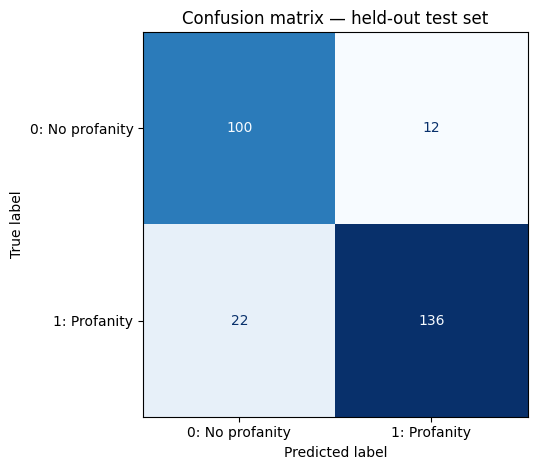

In [34]:
import json
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

metrics_path = artifact_dir / "test_metrics.json"
metrics_path.write_text(
    json.dumps(test_metrics, indent=2) + "\n",
    encoding="utf-8",
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["0: No profanity", "1: Profanity"],
)
disp.plot(cmap="Blues", values_format="d", colorbar=False)
disp.ax_.set_title("Confusion matrix — held-out test set")
disp.figure_.tight_layout()
disp.figure_.savefig(artifact_dir / "confusion_matrix.png", dpi=160)
plt.show()

### 3.3 · Inspect errors without changing the model

In [35]:
test_review = test[["kazsandra_id", "text", "label"]].copy()
test_review = test_review.rename(columns={"label": "dataset_label"})
test_review["prediction"] = test_predictions
test_review["score_class_1"] = test_scores
test_review["distance_to_threshold"] = abs(test_scores - threshold)

errors = test_review.loc[
    test_review["dataset_label"] != test_review["prediction"]
].copy()

errors["error_type"] = errors["prediction"].map({1: "FP", 0: "FN"})

examples = (
    errors.sort_values("distance_to_threshold")
    .groupby("error_type", sort=False)
    .head(3)
)

with pd.option_context("display.max_colwidth", None):
    display(examples.round(4))

,kazsandra_id,text,dataset_label,prediction,score_class_1,distance_to_threshold,error_type
339,pla036347pla,Бұл праграма ұнадыма😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎😎 Қазақ босаң йə де🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿🇰🇿,0,1,0.5177,0.0177,FP
711,pla088778pla,Күшті амы шыккан ойын,1,0,0.4807,0.0193,FN
627,pla132378pla,Онша емес қосылмаид,0,1,0.5205,0.0205,FP
293,pla117989pla,Ам да көрінеді,1,0,0.4725,0.0275,FN
1747,pla015413pla,Е мына қотақ неге ашылмай тұр қазақ тілі үшін жаңартып едім неғып тұр,1,0,0.4703,0.0297,FN
507,pla129420pla,Қазақша жоқққққққ,0,1,0.5374,0.0374,FP


### Test results

We evaluated the saved model on 270 held-out comments. The decision
threshold was 0.50 and was selected using the validation set only.

| Metric for class 1 | Score |
|---|---:|
| Precision | 0.9189 |
| Recall | 0.8608 |
| F1 | 0.8889 |

| Dataset label | Predicted 0 | Predicted 1 |
|---|---:|---:|
| 0 | 100 | 12 |
| 1 | 22 | 136 |

The model missed 22 comments labeled as profane and incorrectly flagged
12 comments labeled as non-profane. These results are measured against
the original dataset labels, which we did not fully verify independently.

The full metrics and confusion matrix are saved in
`artifacts/test_metrics.json` and `artifacts/confusion_matrix.png`.

### Error analysis

We inspected two false positives and one false negative near the
decision threshold of 0.50. Errors are defined relative to the original
dataset labels, which we did not independently verify in full.

- The comment beginning “Бұл праграма ұнадыма” received a score of
  0.5177 and was incorrectly flagged according to the dataset label.
  The comment contains repeated emojis and non-standard spelling, but
  we did not verify which features drove the prediction.
- “Күшті амы шыккан ойын” received a score of 0.4807 and was missed.
  The dataset labels it as profane. The expression “амы” is worth
  reviewing in context before drawing a conclusion about the error.
- “Онша емес қосылмаид” received a score of 0.5205 and was incorrectly
  flagged. It is a short negative review with no clear Kazakh profanity.
  This illustrates why negative sentiment should not be treated as profanity.

A practical improvement would be to add manually verified negative
reviews with no profanity and check ambiguous expressions in the
training data. We did not change the model or threshold after reviewing
the test predictions.

In [36]:
print(f"Test examples: {test_metrics['test_examples']}")
print(f"Threshold:     {test_metrics['threshold']:.2f}")
print(f"Precision:     {test_metrics['precision']:.4f}")
print(f"Recall:        {test_metrics['recall']:.4f}")
print(f"F1:            {test_metrics['f1']:.4f}")
print("Confusion matrix (rows = dataset labels, columns = predictions):")
print(cm)

Test examples: 270
Threshold:     0.50
Precision:     0.9189
Recall:        0.8608
F1:            0.8889
Confusion matrix (rows = dataset labels, columns = predictions):
[[100  12]
 [ 22 136]]


In [37]:
from google.colab import files

files.download(str(model_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
from importlib.metadata import version

for package in ["scikit-learn", "numpy", "scipy", "joblib", "threadpoolctl"]:
    print(f"{package}=={version(package)}")

scikit-learn==1.6.1
numpy==2.4.6
scipy==1.16.3
joblib==1.6.0
threadpoolctl==3.7.0


In [39]:
final_counts = pd.crosstab(
    model_df["split"], model_df["label"]
).reindex(["train", "val", "test"], fill_value=0)

final_counts["Total"] = final_counts.sum(axis=1)
display(final_counts)

assert len(model_df) == 3058
assert len(test) == test_metrics["test_examples"] == 270

label,0,1,Total
split,,,
train,1300,1220,2520
val,110,158,268
test,112,158,270
